# Dropout
Dropout [1], или случайное отключение нейронов, — это метод регуляризации нейронных сетей, при котором во время прямого прохода часть выходных активаций случайным образом обнуляется. В этом упражнении вы реализуете слой dropout и доработаете свою полносвязную сеть так, чтобы в ней можно было (по желанию) использовать dropout.

[1] [Geoffrey E. Hinton et al, "Improving neural networks by preventing co-adaptation of feature detectors", arXiv 2012](https://arxiv.org/abs/1207.0580)

In [1]:
# @title Настройка окружения (запустите эту ячейку первой)
# В Google Colab ячейка подключит ваш Google Диск и перейдёт в папку с лабораторной.
# При локальном запуске (Jupyter) ничего подключать не нужно: достаточно открыть
# ноутбук из папки лабораторной.

# Путь к папке лабораторной внутри «Моего диска», например 'DL/assignment2'.
# Если оставить пустым, папка будет найдена автоматически.
FOLDERNAME = ''  # @param {type:"string"}

import glob
import os
import sys

NOTEBOOK = 'Dropout.ipynb'

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive'
    lab_dir = None
    if FOLDERNAME:
        lab_dir = os.path.join(DRIVE_ROOT, FOLDERNAME.strip('/'))
    else:
        # Ищем на Диске папку, в которой лежат этот ноутбук и пакет dlcv.
        for depth in range(5):
            pattern = os.path.join(DRIVE_ROOT, *['*'] * depth, 'dlcv', '__init__.py')
            found = [os.path.dirname(os.path.dirname(p)) for p in sorted(glob.glob(pattern))]
            found = [d for d in found if os.path.isfile(os.path.join(d, NOTEBOOK))]
            if found:
                # Если копий несколько, берём ту, где ноутбук менялся последним.
                found.sort(key=lambda d: os.path.getmtime(os.path.join(d, NOTEBOOK)),
                           reverse=True)
                lab_dir = found[0]
                if len(found) > 1:
                    print('Найдено несколько папок с лабораторной:', *found, sep='\n  ')
                    print('Используется', lab_dir, '(другую папку можно указать в FOLDERNAME)')
                break
    if lab_dir is None or not os.path.isdir(os.path.join(lab_dir, 'dlcv')):
        raise FileNotFoundError(
            'Не удалось найти папку с лабораторной на Google Диске. Укажите путь '
            'к ней в FOLDERNAME, например: FOLDERNAME = \'DL/assignment2\'')
    os.chdir(lab_dir)

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки лабораторной.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# В Colab используется IPython 7.x, и на Python 3.12+ его расширение autoreload
# не загружается: ему нужен удалённый из Python модуль imp. Подставляем
# совместимую замену (расширению нужна только функция reload).
import IPython
if (sys.version_info >= (3, 12) and IPython.version_info[0] < 8
        and 'imp' not in sys.modules):
    import importlib
    import types
    sys.modules['imp'] = types.ModuleType('imp')
    sys.modules['imp'].reload = importlib.reload

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Рабочая папка: assignment2 (локальный путь скрыт)


> **Как редактировать файлы в Colab.** Часть кода нужно дописывать не в ноутбуках, а в файлах пакета `dlcv/` (например, `dlcv/layers.py`). Откройте панель «Файлы» (значок папки слева), найдите папку лабораторной в `drive/MyDrive/…` и дважды щёлкните по нужному файлу — он откроется в редакторе справа. Сохраните изменения (Ctrl+S). Благодаря `%autoreload` ноутбук подхватит новую версию кода без перезапуска среды выполнения.

In [2]:
# Подготовительная ячейка.
import time
import numpy as np
import matplotlib.pyplot as plt
from dlcv.classifiers.fc_net import *
from dlcv.data_utils import get_CIFAR10_data
from dlcv.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from dlcv.solver import Solver

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0)  # Размер графиков по умолчанию.
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """Возвращает относительную ошибку."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [3]:
# Загружаем (предобработанные) данные CIFAR-10.
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


# Dropout: прямой проход
Реализуйте прямой проход dropout в файле `dlcv/layers.py` (функция `dropout_forward`). Поскольку при обучении и при тестировании dropout ведёт себя по-разному, реализуйте операцию для обоих режимов.

После этого запустите ячейку ниже, чтобы проверить свою реализацию.

In [4]:
np.random.seed(231)
x = np.random.randn(500, 500) + 10

for p in [0.25, 0.4, 0.7]:
    out, _ = dropout_forward(x, {'mode': 'train', 'p': p})
    out_test, _ = dropout_forward(x, {'mode': 'test', 'p': p})

    print('Проверка при p = ', p)
    print('Среднее значение входа: ', x.mean())
    print('Среднее значение выхода при обучении: ', out.mean())
    print('Среднее значение выхода при тестировании: ', out_test.mean())
    print('Доля обнулённых выходов при обучении: ', (out == 0).mean())
    print('Доля обнулённых выходов при тестировании: ', (out_test == 0).mean())
    print()

Проверка при p =  0.25
Среднее значение входа:  10.0002078784775
Среднее значение выхода при обучении:  10.014059116977283
Среднее значение выхода при тестировании:  10.0002078784775
Доля обнулённых выходов при обучении:  0.749784
Доля обнулённых выходов при тестировании:  0.0

Проверка при p =  0.4
Среднее значение входа:  10.0002078784775
Среднее значение выхода при обучении:  9.977917658761159
Среднее значение выхода при тестировании:  10.0002078784775
Доля обнулённых выходов при обучении:  0.600796
Доля обнулённых выходов при тестировании:  0.0

Проверка при p =  0.7
Среднее значение входа:  10.0002078784775
Среднее значение выхода при обучении:  9.987811912159428
Среднее значение выхода при тестировании:  10.0002078784775
Доля обнулённых выходов при обучении:  0.30074
Доля обнулённых выходов при тестировании:  0.0



# Dropout: обратный проход
Реализуйте обратный проход dropout в файле `dlcv/layers.py` (функция `dropout_backward`). Затем запустите следующую ячейку, чтобы проверить реализацию с помощью численной проверки градиента.

In [5]:
np.random.seed(231)
x = np.random.randn(10, 10) + 10
dout = np.random.randn(*x.shape)

dropout_param = {'mode': 'train', 'p': 0.2, 'seed': 123}
out, cache = dropout_forward(x, dropout_param)
dx = dropout_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda xx: dropout_forward(xx, dropout_param)[0], x, dout)

# Ошибка должна быть порядка 1e-10 или меньше.
print('относительная ошибка dx: ', rel_error(dx, dx_num))

относительная ошибка dx:  5.44560814873387e-11


## Вопрос 1
Что произойдёт, если в слое dropout не делить на `p` значения, которые пропускает инвертированный dropout? Почему так происходит?

**Ваш ответ:** Если не делить сохранённые значения на вероятность сохранения p, математическое ожидание выхода при обучении станет p·x вместо x. При тестировании dropout отключён, поэтому масштаб активаций изменится; этот сдвиг накапливается при нескольких слоях. Деление на p сохраняет ожидаемый масштаб и позволяет использовать при тестировании обычный прямой проход.


# Полносвязные сети с dropout
Доработайте класс `FullyConnectedNet` в файле `dlcv/classifiers/fc_net.py` так, чтобы сеть использовала dropout (места для кода отмечены `TODO`). А именно: если конструктор сети получает параметр `dropout_keep_ratio` со значением, отличным от 1, сеть должна добавлять слой dropout сразу после каждой нелинейности ReLU. После этого запустите ячейку ниже, чтобы проверить реализацию с помощью численной проверки градиента.

In [6]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for dropout_keep_ratio in [1, 0.75, 0.5]:
    print('Проверка при dropout_keep_ratio = ', dropout_keep_ratio)
    model = FullyConnectedNet(
        [H1, H2],
        input_dim=D,
        num_classes=C,
        weight_scale=5e-2,
        dtype=np.float64,
        dropout_keep_ratio=dropout_keep_ratio,
        seed=123
    )

    loss, grads = model.loss(X, y)
    print('Начальные потери: ', loss)

    # Относительные ошибки должны быть порядка 1e-6 или меньше.
    # При dropout_keep_ratio=1 ошибка для W2 порядка 1e-5 тоже допустима.
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print('%s — относительная ошибка: %.2e' % (name, rel_error(grad_num, grads[name])))
    print()

Проверка при dropout_keep_ratio =  1
Начальные потери:  2.3004790897684924


W1 — относительная ошибка: 1.48e-07


W2 — относительная ошибка: 2.21e-05


W3 — относительная ошибка: 3.53e-07
b1 — относительная ошибка: 5.38e-09
b2 — относительная ошибка: 2.09e-09
b3 — относительная ошибка: 5.80e-11

Проверка при dropout_keep_ratio =  0.75
Начальные потери:  2.302371489704412


W1 — относительная ошибка: 1.90e-07


W2 — относительная ошибка: 4.76e-06


W3 — относительная ошибка: 2.60e-08
b1 — относительная ошибка: 4.73e-09
b2 — относительная ошибка: 1.82e-09
b3 — относительная ошибка: 1.70e-10

Проверка при dropout_keep_ratio =  0.5
Начальные потери:  2.3042759220785896


W1 — относительная ошибка: 3.11e-07


W2 — относительная ошибка: 1.84e-08


W3 — относительная ошибка: 5.35e-08
b1 — относительная ошибка: 5.37e-09
b2 — относительная ошибка: 2.99e-09
b3 — относительная ошибка: 1.13e-10



# Эксперимент с регуляризацией
В качестве эксперимента обучим две двухслойные сети на 500 обучающих примерах: одну без dropout, а другую — с вероятностью сохранить нейрон 0.25. Затем построим графики того, как меняется точность обеих сетей на обучающей и валидационной выборках в ходе обучения.

In [7]:
# Обучаем две одинаковые сети: одну с dropout, другую без него.
np.random.seed(231)
num_train = 500
small_data = {
    'X_train': data['X_train'][:num_train],
    'y_train': data['y_train'][:num_train],
    'X_val': data['X_val'],
    'y_val': data['y_val'],
}

solvers = {}
dropout_choices = [1, 0.25]
for dropout_keep_ratio in dropout_choices:
    model = FullyConnectedNet(
        [500],
        dropout_keep_ratio=dropout_keep_ratio
    )
    print(dropout_keep_ratio)

    solver = Solver(
        model,
        small_data,
        num_epochs=25,
        batch_size=100,
        update_rule='adam',
        optim_config={'learning_rate': 5e-4,},
        verbose=True,
        print_every=100
    )
    solver.train()
    solvers[dropout_keep_ratio] = solver
    print()

1
(Итерация 1 / 125) потери: 7.856643


(Эпоха 0 / 25) точность на обучении: 0.260000; на валидации: 0.184000


(Эпоха 1 / 25) точность на обучении: 0.416000; на валидации: 0.258000


(Эпоха 2 / 25) точность на обучении: 0.482000; на валидации: 0.276000


(Эпоха 3 / 25) точность на обучении: 0.532000; на валидации: 0.277000


(Эпоха 4 / 25) точность на обучении: 0.600000; на валидации: 0.271000


... (45 outputs left out)

(Эпоха 22 / 25) точность на обучении: 0.902000; на валидации: 0.296000


(Эпоха 23 / 25) точность на обучении: 0.892000; на валидации: 0.309000


(Эпоха 24 / 25) точность на обучении: 0.892000; на валидации: 0.324000


(Эпоха 25 / 25) точность на обучении: 0.888000; на валидации: 0.328000



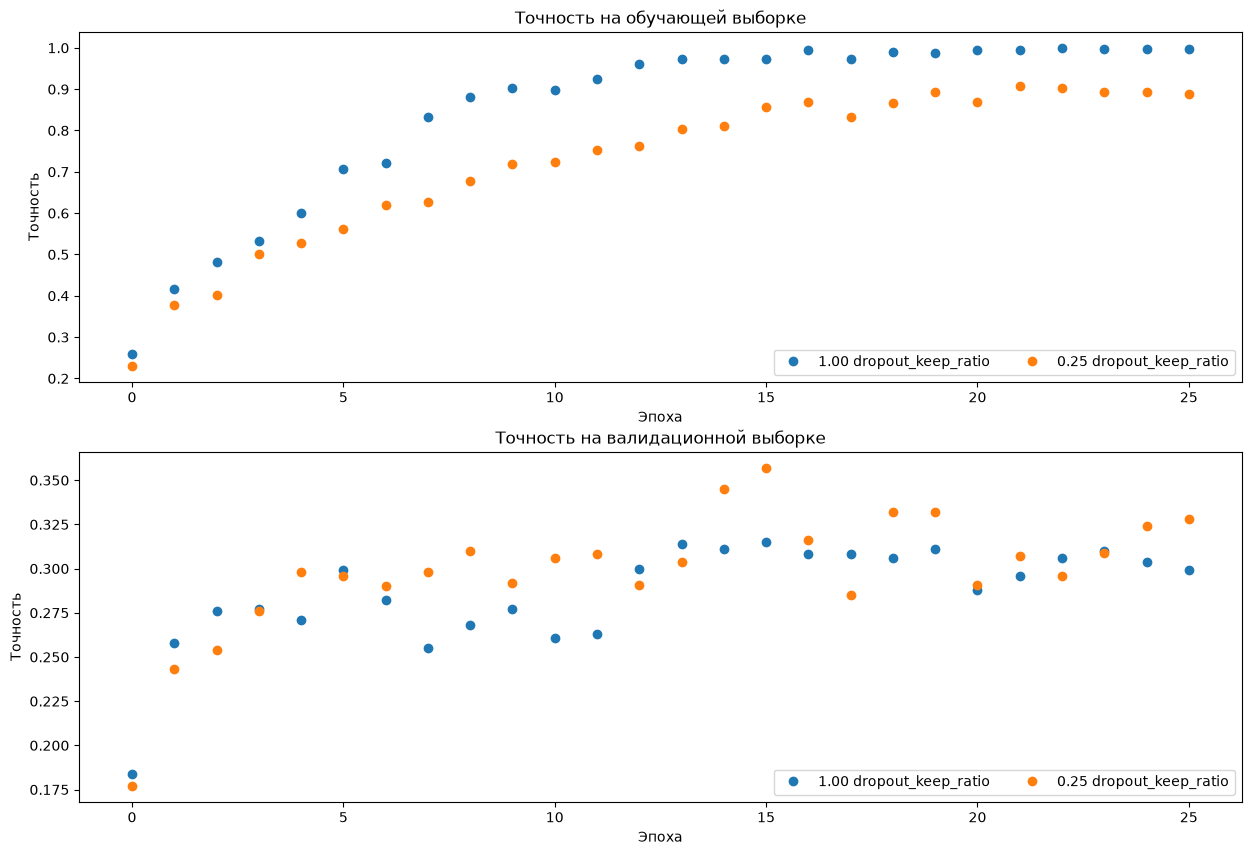

In [8]:
# Строим графики точности обеих моделей на обучающей и валидационной выборках.
train_accs = []
val_accs = []
for dropout_keep_ratio in dropout_choices:
    solver = solvers[dropout_keep_ratio]
    train_accs.append(solver.train_acc_history[-1])
    val_accs.append(solver.val_acc_history[-1])

plt.subplot(2, 1, 1)
for dropout_keep_ratio in dropout_choices:
    plt.plot(
        solvers[dropout_keep_ratio].train_acc_history, 'o', label='%.2f dropout_keep_ratio' % dropout_keep_ratio)
plt.title('Точность на обучающей выборке')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend(ncol=2, loc='lower right')

plt.subplot(2, 1, 2)
for dropout_keep_ratio in dropout_choices:
    plt.plot(
        solvers[dropout_keep_ratio].val_acc_history, 'o', label='%.2f dropout_keep_ratio' % dropout_keep_ratio)
plt.title('Точность на валидационной выборке')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend(ncol=2, loc='lower right')

plt.gcf().set_size_inches(15, 10)
plt.show()

## Вопрос 2
Сравните точность на валидационной и обучающей выборках с dropout и без него. Что ваши результаты говорят о dropout как о методе регуляризации?

**Ваш ответ:** Dropout ограничивает совместную подстройку нейронов и усложняет запоминание обучающей выборки. Обычно точность на обучении снижается, а разрыв между обучением и валидацией уменьшается; валидационная точность может улучшиться. Сильный dropout (здесь сохраняется только четверть нейронов) также может вызвать недообучение, поэтому улучшение валидации не гарантировано. Конкретное сравнение выполненных запусков приведено на графиках выше; оценка train/val выполняется с отключённым dropout.


В выполненном запуске на последней (25-й) эпохе без dropout: train 99.8%, validation 29.9%; при p=0.25: train 88.8%, validation 32.8%. Разрыв уменьшился с 69.9 до 56.0 процентных пунктов, а validation выросла на 2.9 п.п. Это согласуется с регуляризующим действием dropout. Эти значения относятся к последней эпохе на графике; Solver затем восстанавливает веса лучшей эпохи по validation.